# IMPORT LIBRARIES

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from scipy.stats import spearmanr

# Dataset
from sklearn.datasets import (
    load_breast_cancer,
    load_wine,
    make_classification
)

# Chia dữ liệu và tối ưu mô hình
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score,
    cross_val_predict,
    StratifiedKFold,
    RepeatedStratifiedKFold
)

# Các mô hình Machine Learning
from sklearn.tree import (
    DecisionTreeClassifier,
    export_text,
    plot_tree
)

from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    VotingClassifier,
    StackingClassifier
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

# Tiền xử lý
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Feature Importance
from sklearn.inspection import permutation_importance

# Đánh giá mô hình
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    recall_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42

# Load data

In [3]:


def load_dataset(name="breast_cancer"):

    if name == "breast_cancer":
        data = load_breast_cancer()

        X = data.data
        y = data.target
        feature_names = list(data.feature_names)

    elif name == "wine":
        data = load_wine()

        X = data.data
        y = data.target
        feature_names = list(data.feature_names)

    elif name == "synthetic":
        X, y = make_classification(
            n_samples=1000,
            n_features=20,
            n_informative=15,
            n_redundant=5,
            random_state=2
        )

        feature_names = [
            f"feature_{i}" for i in range(X.shape[1])
        ]

    else:
        raise ValueError("Dataset không hợp lệ!")

    return X, y, feature_names

In [4]:
X, y, feature_names = load_dataset("breast_cancer")

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)
print("Số lượng nhãn:", np.unique(y))

Kích thước X: (569, 30)
Kích thước y: (569,)
Số lượng nhãn: [0 1]


# DATA MANAGER

In [5]:


class DataManager:

    def __init__(
        self,
        X,
        y,
        test_size=0.2,
        val_size=0.2,
        random_state=42
    ):

        # Bước 1: Chia Train_val và Test
        (
            self.X_train_val,
            self.__X_test,
            self.y_train_val,
            self.__y_test
        ) = train_test_split(
            X,
            y,
            test_size=test_size,
            stratify=y,
            random_state=random_state
        )

        # Bước 2: Chia Train_val thành Train và Val
        (
            self.X_train,
            self.X_val,
            self.y_train,
            self.y_val
        ) = train_test_split(
            self.X_train_val,
            self.y_train_val,
            test_size=val_size,
            stratify=self.y_train_val,
            random_state=random_state
        )

        # Trạng thái sử dụng tập Test
        self.__test_used = False

    # Lấy dữ liệu huấn luyện
    def get_train(self):
        return self.X_train, self.y_train

    # Lấy dữ liệu validation
    def get_val(self):
        return self.X_val, self.y_val

    # Lấy toàn bộ dữ liệu Train_val
    def get_train_val(self):
        return self.X_train_val, self.y_train_val

    # Kiểm tra phân bố nhãn
    def show_distribution(self):

        datasets = {
            "Train_val": self.y_train_val,
            "Train": self.y_train,
            "Validation": self.y_val,
            "Test": self.__y_test
        }

        rows = []

        for name, labels in datasets.items():

            counts = pd.Series(labels).value_counts()
            ratios = pd.Series(labels).value_counts(
                normalize=True
            )

            row = {
                "Dataset": name,
                "Total": len(labels)
            }

            for label in sorted(np.unique(labels)):
                row[f"Class {label} count"] = counts[label]
                row[f"Class {label} ratio"] = (
                    f"{ratios[label] * 100:.2f}%"
                )

            rows.append(row)

        return pd.DataFrame(rows)

    # Chỉ cho phép đánh giá Test một lần
    def evaluate_test(self, model):

        if self.__test_used:
            raise RuntimeError(
                "Tập Test đã được sử dụng. "
                "Không được phép đánh giá lại!"
            )

        # Khóa trước khi thực hiện đánh giá
        self.__test_used = True

        y_pred = model.predict(self.__X_test)

        return {
            "accuracy": accuracy_score(
                self.__y_test, y_pred
            ),

            "f1_macro": f1_score(
                self.__y_test,
                y_pred,
                average="macro"
            ),

            "confusion_matrix": confusion_matrix(
                self.__y_test, y_pred
            ),

            "classification_report": classification_report(
                self.__y_test,
                y_pred,
                zero_division=0
            )
        }

# bai 1

In [6]:
# Nạp dữ liệu
X, y, feature_names = load_dataset("breast_cancer")

# Khởi tạo đối tượng DataManager
data_manager = DataManager(
    X,
    y,
    test_size=0.2,
    val_size=0.2,
    random_state=42
)

# Lấy dữ liệu từ DataManager
X_train, y_train = data_manager.get_train()

X_val, y_val = data_manager.get_val()

# Kiểm tra phân bố nhãn
print(data_manager.show_distribution())

      Dataset  Total  Class 0 count Class 0 ratio  Class 1 count Class 1 ratio
0   Train_val    455            170        37.36%            285        62.64%
1       Train    364            136        37.36%            228        62.64%
2  Validation     91             34        37.36%             57        62.64%
3        Test    114             42        36.84%             72        63.16%


|--- worst concave points <= 0.15
|   |--- worst area <= 929.80
|   |   |--- worst perimeter <= 102.40
|   |   |   |--- class: 1
|   |   |--- worst perimeter >  102.40
|   |   |   |--- class: 1
|   |--- worst area >  929.80
|   |   |--- symmetry error <= 0.01
|   |   |   |--- class: 1
|   |   |--- symmetry error >  0.01
|   |   |   |--- class: 0
|--- worst concave points >  0.15
|   |--- worst radius <= 12.80
|   |   |--- class: 1
|   |--- worst radius >  12.80
|   |   |--- fractal dimension error <= 0.01
|   |   |   |--- class: 0
|   |   |--- fractal dimension error >  0.01
|   |   |   |--- class: 1



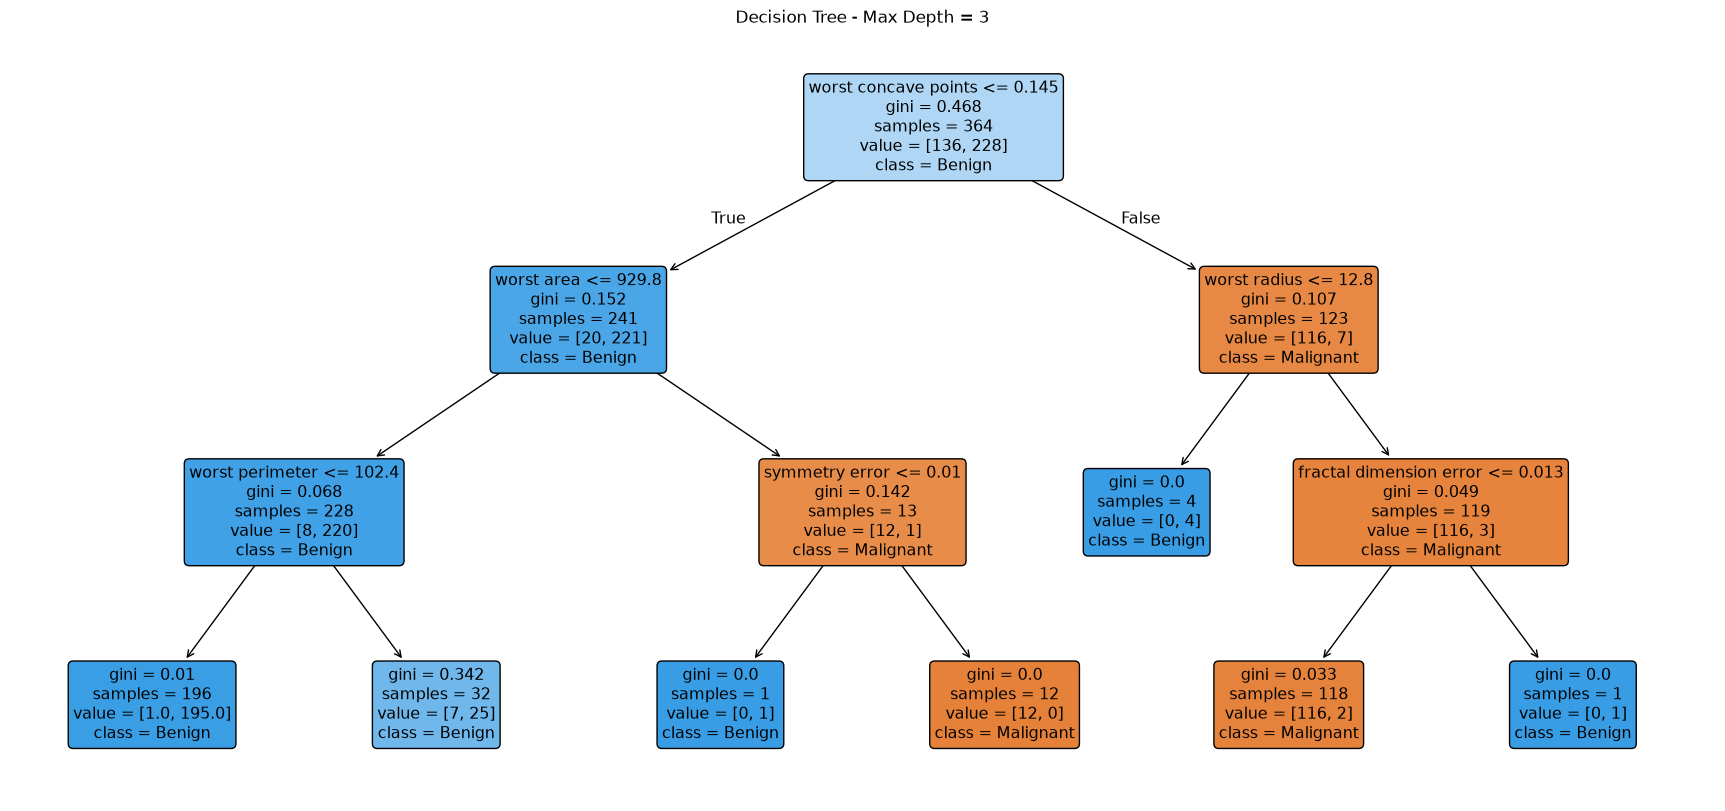

Root feature index: 27
Root feature: worst concave points
Root threshold: 0.14545000344514847
Số mẫu kiểm tra: 91
Hàm trace và predict cho kết quả giống nhau!
Train Accuracy: 0.9725
Validation Accuracy: 0.9451
Accuracy Gap: 0.0275

--- Decision Tree ---
Root feature: worst concave points
Most important feature: worst concave points
Max importance: 0.7849

--- Random Forest ---
Most important feature: worst perimeter
Max importance: 0.1473

--- Kiểm tra nhận định ---
Root feature là đặc trưng quan trọng nhất: True
RF max importance nhỏ hơn DT max importance: True

--- Bảng Feature Importance ---
                Feature  Decision Tree  Random Forest
   worst concave points       0.784878       0.129681
             worst area       0.126345       0.134920
           worst radius       0.047908       0.075027
        worst perimeter       0.016359       0.147311
fractal dimension error       0.012484       0.005072
         symmetry error       0.012026       0.002491
         mean concav

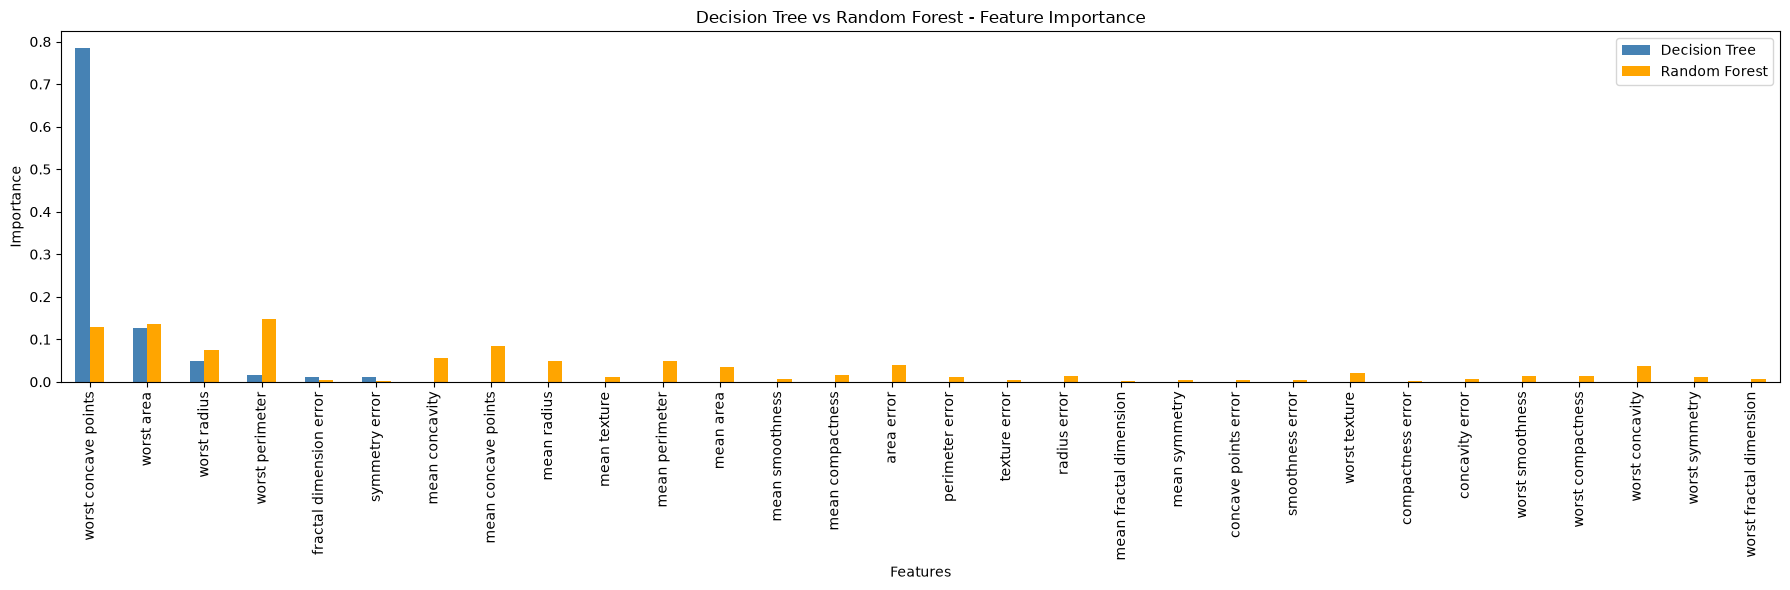

In [7]:



model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

# ==========================================
# CÂU A: IN QUY TẮC CỦA CÂY QUYẾT ĐỊNH
# ==========================================


rules = export_text(
    model,
    feature_names=feature_names
)

print(rules)

# Vẽ cây quyết định
plt.figure(figsize=(22, 10))

plot_tree(
    model,
    feature_names=feature_names,
    class_names=["Malignant", "Benign"],
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Max Depth = 3")
plt.show()


# ==========================================
# CÂU B: XÁC ĐỊNH ĐẶC TRƯNG VÀ NGƯỠNG NÚT GỐC
# ==========================================

root_feature_index = model.tree_.feature[0]
root_feature = feature_names[root_feature_index]
root_threshold = model.tree_.threshold[0]

print("Root feature index:", root_feature_index)
print("Root feature:", root_feature)
print("Root threshold:", root_threshold)


# ==========================================
# CÂU C: TỰ XÂY DỰNG HÀM TRACE
# ==========================================



def trace(model, x):

    tree = model.tree_

    # Chuyển kiểu dữ liệu giống sklearn
    x = np.asarray(x, dtype=np.float32)

    # Bắt đầu từ nút gốc
    node = 0

    # Duyệt cây đến khi gặp nút lá
    while tree.children_left[node] != -1:

        feature_index = tree.feature[node]
        threshold = tree.threshold[node]

        if x[feature_index] <= threshold:
            node = tree.children_left[node]
        else:
            node = tree.children_right[node]

    # Tìm lớp có giá trị lớn nhất tại nút lá
    class_index = np.argmax(tree.value[node])

    # Trả về nhãn dự đoán
    return model.classes_[class_index]


# Dự đoán bằng hàm trace tự xây dựng
y_pred_manual = np.array([
    trace(model, x) for x in X_val
])

# Dự đoán bằng sklearn
y_pred_sklearn = model.predict(X_val)

# Kiểm tra hai kết quả dự đoán
assert np.array_equal(
    y_pred_manual,
    y_pred_sklearn
), "Hàm trace dự đoán không chính xác!"

print("Số mẫu kiểm tra:", len(X_val))
print("Hàm trace và predict cho kết quả giống nhau!")

# Đánh giá trên Train và Validation
train_acc = accuracy_score(
    y_train,
    model.predict(X_train)
)

val_acc = accuracy_score(
    y_val,
    y_pred_manual
)

print(f"Train Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Accuracy Gap: {train_acc - val_acc:.4f}")


# ==========================================
# CÂU D: SO SÁNH FEATURE IMPORTANCE
# ==========================================



# 1. Feature Importance của Decision Tree

tree_importances = model.feature_importances_

tree_max_index = np.argmax(tree_importances)

tree_max_feature = feature_names[tree_max_index]

tree_max_importance = tree_importances[tree_max_index]

print("\n--- Decision Tree ---")

print("Root feature:", root_feature)
print("Most important feature:", tree_max_feature)
print(f"Max importance: {tree_max_importance:.4f}")


# 2. Huấn luyện Random Forest

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)


# 3. Feature Importance của Random Forest

rf_importances = rf_model.feature_importances_

rf_max_index = np.argmax(rf_importances)

rf_max_feature = feature_names[rf_max_index]

rf_max_importance = rf_importances[rf_max_index]

print("\n--- Random Forest ---")

print("Most important feature:", rf_max_feature)
print(f"Max importance: {rf_max_importance:.4f}")


# 4. Kiểm tra hai nhận định của đề bài

print("\n--- Kiểm tra nhận định ---")

print(
    "Root feature là đặc trưng quan trọng nhất:",
    root_feature == tree_max_feature
)

print(
    "RF max importance nhỏ hơn DT max importance:",
    rf_max_importance < tree_max_importance
)


# 5. Tạo bảng so sánh Feature Importance

df_importance = pd.DataFrame({
    "Feature": feature_names,
    "Decision Tree": tree_importances,
    "Random Forest": rf_importances
})

df_importance = df_importance.sort_values(
    by="Decision Tree",
    ascending=False
)

print("\n--- Bảng Feature Importance ---")

print(df_importance.to_string(index=False))


# 6. Vẽ biểu đồ so sánh Feature Importance

df_importance.set_index("Feature").plot(
    kind="bar",
    figsize=(18, 6),
    color=["steelblue", "orange"]
)

plt.title("Decision Tree vs Random Forest - Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()


# 7. Kiểm chứng bằng assert

assert root_feature == tree_max_feature, (
    "Root feature không phải đặc trưng quan trọng nhất!"
)

assert rf_max_importance < tree_max_importance, (
    "RF max importance không nhỏ hơn DT max importance!"
)



# bai 2

 max_depth  train_acc  val_acc      gap
         1   0.925824 0.890110 0.035714
         2   0.967033 0.945055 0.021978
         3   0.972527 0.945055 0.027473
         4   0.986264 0.945055 0.041209
         5   0.994505 0.934066 0.060440
         6   1.000000 0.945055 0.054945
         7   1.000000 0.945055 0.054945
         8   1.000000 0.945055 0.054945
         9   1.000000 0.945055 0.054945
        10   1.000000 0.945055 0.054945
        11   1.000000 0.945055 0.054945
        12   1.000000 0.945055 0.054945
        13   1.000000 0.945055 0.054945
        14   1.000000 0.945055 0.054945
        15   1.000000 0.945055 0.054945
        16   1.000000 0.945055 0.054945
        17   1.000000 0.945055 0.054945
        18   1.000000 0.945055 0.054945
        19   1.000000 0.945055 0.054945
        20   1.000000 0.945055 0.054945
      <NA>   1.000000 0.945055 0.054945


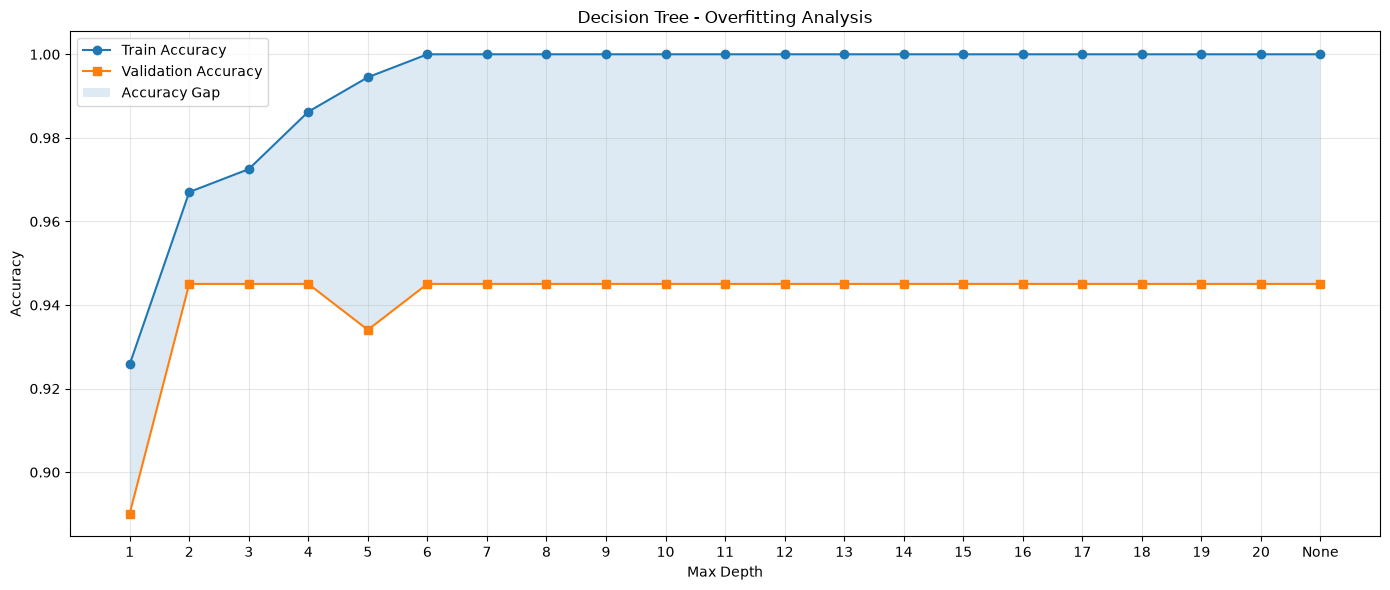


--- Best Decision Tree ---
Best max_depth: 2
Actual depth: 2
Train Accuracy: 0.9670
Validation Accuracy: 0.9451
Gap: 0.0220

--- Unlimited Decision Tree ---
Actual depth: 6
Number of leaves: 16
Train Accuracy: 1.0000
Validation Accuracy: 0.9451
Gap: 0.0549

--- Kiểm chứng các nhận định ---
Unlimited Train Accuracy = 1.0: True
Unlimited Gap > Best Gap: True
Train Accuracy không giảm: True


In [8]:
# ==========================================
# BÀI 2: OVERFITTING A SINGLE TREE
# ==========================================

# Lấy dữ liệu từ DataManager
X_train, y_train = data_manager.get_train()
X_val, y_val = data_manager.get_val()


# ==========================================
# CÂU A: HUẤN LUYỆN 21 MÔ HÌNH
# ==========================================


# Độ sâu từ 1 đến 20 và không giới hạn
depths = list(range(1, 21)) + [None]

# Lưu kết quả đánh giá
results = []

# Lưu các mô hình đã huấn luyện
models = {}

for depth in depths:

    # Khởi tạo mô hình
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    # Huấn luyện mô hình
    model.fit(X_train, y_train)

    # Dự đoán trên Train và Validation
    y_train_pred = model.predict(X_train)
    y_val_pred = model.predict(X_val)

    # Tính Accuracy
    train_acc = accuracy_score(y_train, y_train_pred)
    val_acc = accuracy_score(y_val, y_val_pred)

    # Tính độ chênh lệch Accuracy
    gap = train_acc - val_acc

    # Lưu kết quả
    results.append({
        "max_depth": depth,
        "train_acc": train_acc,
        "val_acc": val_acc,
        "gap": gap
    })

    # Lưu mô hình tương ứng với độ sâu
    models[depth] = model


# Tạo DataFrame
df_depth = pd.DataFrame(results)

# Sử dụng kiểu Int64 cho phép chứa giá trị thiếu
df_depth["max_depth"] = df_depth["max_depth"].astype("Int64")

print(df_depth.to_string(index=False))


# ==========================================
# CÂU B: VẼ BIỂU ĐỒ ACCURACY
# ==========================================



# Chuyển độ sâu thành chuỗi để hiển thị None
depth_labels = [str(depth) for depth in depths]

plt.figure(figsize=(14, 6))

# Đường Train Accuracy
plt.plot(
    depth_labels,
    df_depth["train_acc"],
    marker="o",
    label="Train Accuracy"
)

# Đường Validation Accuracy
plt.plot(
    depth_labels,
    df_depth["val_acc"],
    marker="s",
    label="Validation Accuracy"
)

# Tô vùng chênh lệch giữa Train và Validation
plt.fill_between(
    depth_labels,
    df_depth["train_acc"],
    df_depth["val_acc"],
    alpha=0.15,
    label="Accuracy Gap"
)

plt.title("Decision Tree - Overfitting Analysis")
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ==========================================
# CÂU C: TÌM ĐỘ SÂU TỐT NHẤT
# ==========================================



# Tìm dòng có Validation Accuracy cao nhất
best_index = df_depth["val_acc"].idxmax()

best_row = df_depth.loc[best_index]

# Lấy độ sâu tốt nhất
best_depth = depths[best_index]

# Lấy các thông số của mô hình tốt nhất
best_train_acc = best_row["train_acc"]
best_val_acc = best_row["val_acc"]
best_gap = best_row["gap"]

# Lấy mô hình tốt nhất
best_model = models[best_depth]

print("\n--- Best Decision Tree ---")

print("Best max_depth:", best_depth)
print("Actual depth:", best_model.get_depth())
print(f"Train Accuracy: {best_train_acc:.4f}")
print(f"Validation Accuracy: {best_val_acc:.4f}")
print(f"Gap: {best_gap:.4f}")


# ==========================================
# THÔNG TIN CÂY KHÔNG GIỚI HẠN ĐỘ SÂU
# ==========================================

# Lấy dòng có max_depth=None
unlimited_row = df_depth[
    df_depth["max_depth"].isna()
].iloc[0]

unlimited_train_acc = unlimited_row["train_acc"]
unlimited_val_acc = unlimited_row["val_acc"]
unlimited_gap = unlimited_row["gap"]

# Lấy mô hình không giới hạn độ sâu
unlimited_model = models[None]

print("\n--- Unlimited Decision Tree ---")

print("Actual depth:", unlimited_model.get_depth())
print("Number of leaves:", unlimited_model.get_n_leaves())

print(f"Train Accuracy: {unlimited_train_acc:.4f}")
print(f"Validation Accuracy: {unlimited_val_acc:.4f}")
print(f"Gap: {unlimited_gap:.4f}")


# ==========================================
# KIỂM CHỨNG 3 NHẬN ĐỊNH CỦA ĐỀ BÀI
# ==========================================

print("\n--- Kiểm chứng các nhận định ---")

# Nhận định 1:
# Cây không giới hạn có Train Accuracy bằng 1
condition_1 = unlimited_train_acc == 1.0


# Nhận định 2:
# Gap của cây không giới hạn lớn hơn cây tốt nhất
condition_2 = unlimited_gap > best_gap


# Nhận định 3:
# Train Accuracy không giảm khi depth tăng từ 1 đến 20
limited_rows = df_depth[
    df_depth["max_depth"].notna()
]

train_accuracies = limited_rows["train_acc"].to_numpy()

condition_3 = np.all(
    np.diff(train_accuracies) >= 0
)


# In kết quả kiểm chứng
print("Unlimited Train Accuracy = 1.0:", condition_1)

print("Unlimited Gap > Best Gap:", condition_2)

print("Train Accuracy không giảm:", condition_3)


# Kiểm chứng bằng assert
assert condition_1, "Unlimited Train Accuracy khác 1.0!"

assert condition_2, "Unlimited Gap không lớn hơn Best Gap!"

assert condition_3, "Train Accuracy bị giảm khi tăng độ sâu!"



# bai 3

Bootstrap 1: Total = 364, Unique = 233
Bootstrap 2: Total = 364, Unique = 223
Bootstrap 3: Total = 364, Unique = 236
Bootstrap 4: Total = 364, Unique = 235
Bootstrap 5: Total = 364, Unique = 232
Bootstrap 6: Total = 364, Unique = 236
Bootstrap 7: Total = 364, Unique = 232
Bootstrap 8: Total = 364, Unique = 225
Bootstrap 9: Total = 364, Unique = 226
Bootstrap 10: Total = 364, Unique = 230
Bootstrap 11: Total = 364, Unique = 237
Bootstrap 12: Total = 364, Unique = 233
Bootstrap 13: Total = 364, Unique = 227
Bootstrap 14: Total = 364, Unique = 224
Bootstrap 15: Total = 364, Unique = 229
Tree 1: Depth = 7, Leaves = 14
Tree 2: Depth = 5, Leaves = 8
Tree 3: Depth = 6, Leaves = 13
Tree 4: Depth = 6, Leaves = 13
Tree 5: Depth = 5, Leaves = 12
Tree 6: Depth = 5, Leaves = 11
Tree 7: Depth = 6, Leaves = 13
Tree 8: Depth = 5, Leaves = 9
Tree 9: Depth = 6, Leaves = 13
Tree 10: Depth = 6, Leaves = 12
Tree 11: Depth = 6, Leaves = 14
Tree 12: Depth = 5, Leaves = 12
Tree 13: Depth = 5, Leaves = 9
Tree 

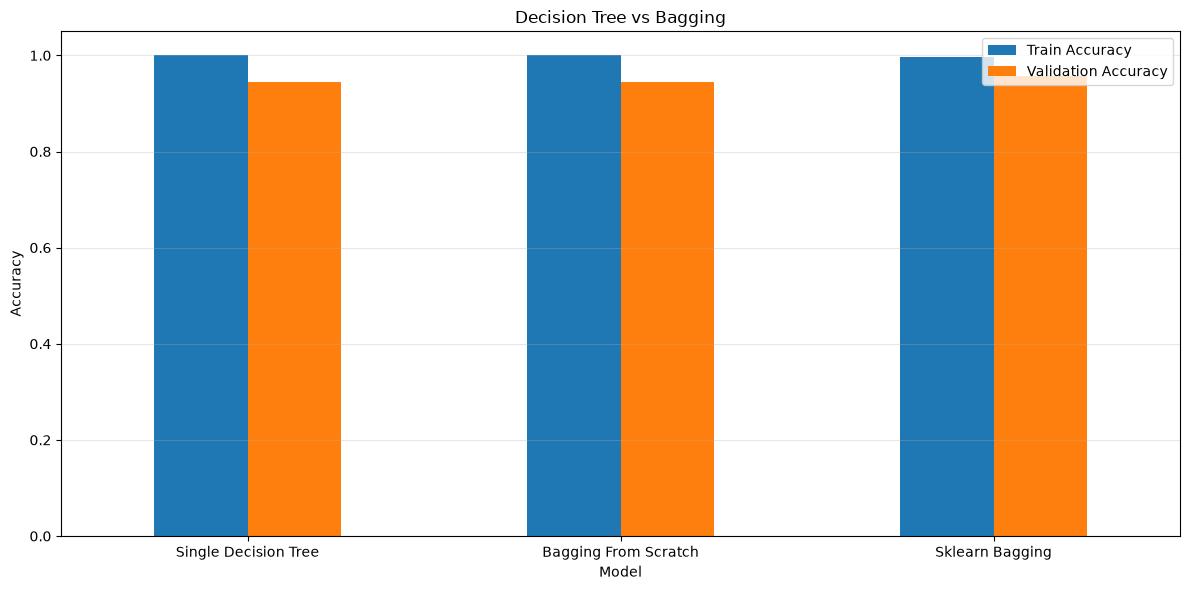

Bagging >= Single Tree: True
Accuracy Difference <= 0.03: True


In [9]:
# ==========================================
# BÀI 3: BAGGING FROM SCRATCH
# ==========================================

# Lấy dữ liệu từ DataManager
X_train, y_train = data_manager.get_train()
X_val, y_val = data_manager.get_val()

# Số lượng cây
n_estimators = 15

# Số lượng mẫu huấn luyện
n_train = len(X_train)

# Khởi tạo bộ sinh số ngẫu nhiên
rng = np.random.default_rng(42)


# ==========================================
# CÂU A: TẠO 15 TẬP BOOTSTRAP
# ==========================================

bootstrap_indices = []

for i in range(n_estimators):

    # Lấy mẫu ngẫu nhiên có hoàn lại
    indices = rng.integers(0, n_train, n_train)

    # Lưu danh sách chỉ số
    bootstrap_indices.append(indices)

    print(
        f"Bootstrap {i + 1}: "
        f"Total = {len(indices)}, "
        f"Unique = {len(np.unique(indices))}"
    )


# ==========================================
# CÂU B: HUẤN LUYỆN 15 DECISION TREE
# ==========================================



bagging_models = []

for i, indices in enumerate(bootstrap_indices):

    # Lấy dữ liệu Bootstrap
    X_bootstrap = X_train[indices]
    y_bootstrap = y_train[indices]

    # Khởi tạo Decision Tree không giới hạn độ sâu
    model = DecisionTreeClassifier(
        max_depth=None,
        random_state=42
    )

    # Huấn luyện trên tập Bootstrap
    model.fit(X_bootstrap, y_bootstrap)

    # Lưu mô hình
    bagging_models.append(model)

    print(
        f"Tree {i + 1}: "
        f"Depth = {model.get_depth()}, "
        f"Leaves = {model.get_n_leaves()}"
    )


# ==========================================
# CÂU C: MAJORITY VOTING
# ==========================================



def bagging_predict(models, X):

    predictions = []

    # Cho từng cây dự đoán
    for model in models:

        y_pred = model.predict(X)

        predictions.append(y_pred)

    # Chuyển thành ma trận NumPy
    predictions = np.array(predictions)

    # Tính trung bình dự đoán của các cây
    mean_predictions = np.mean(
        predictions,
        axis=0
    )

    # Bỏ phiếu đa số cho bài toán nhãn 0 và 1
    final_predictions = (
        mean_predictions >= 0.5
    ).astype(int)

    return final_predictions


# Dự đoán trên Validation
y_bag_pred = bagging_predict(
    bagging_models,
    X_val
)

print("Số mẫu dự đoán:", len(y_bag_pred))

print("10 nhãn dự đoán đầu tiên:", y_bag_pred[:10])

print("10 nhãn thực tế đầu tiên:", y_val[:10])


# ==========================================
# CÂU D: SO SÁNH BAGGING VÀ DECISION TREE
# ==========================================



# Accuracy của Bagging tự xây dựng
bag_acc = accuracy_score(
    y_val,
    y_bag_pred
)

# Khởi tạo một Decision Tree đơn lẻ
single_model = DecisionTreeClassifier(
    max_depth=None,
    random_state=42
)

# Huấn luyện trên toàn bộ tập Train
single_model.fit(X_train, y_train)

# Dự đoán trên Validation
y_single_pred = single_model.predict(X_val)

# Accuracy của Decision Tree đơn lẻ
single_acc = accuracy_score(
    y_val,
    y_single_pred
)

print(f"Bagging Accuracy: {bag_acc:.4f}")

print(f"Single Tree Accuracy: {single_acc:.4f}")

print(
    f"Accuracy Improvement: "
    f"{bag_acc - single_acc:.4f}"
)


# ==========================================
# CÂU E: SỬ DỤNG BAGGINGCLASSIFIER
# ==========================================


sklearn_bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=15,
    max_samples=1.0,
    max_features=1.0,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# Huấn luyện
sklearn_bagging.fit(X_train, y_train)

# Dự đoán trên Validation
y_sklearn_pred = sklearn_bagging.predict(X_val)

# Tính Accuracy
sklearn_bag_acc = accuracy_score(
    y_val,
    y_sklearn_pred
)

# Tính độ chênh lệch
difference = abs(sklearn_bag_acc - bag_acc)

print(f"Manual Bagging Accuracy: {bag_acc:.4f}")

print(f"Sklearn Bagging Accuracy: {sklearn_bag_acc:.4f}")

print(f"Accuracy Difference: {difference:.4f}")


# ==========================================
# TẠO BẢNG SO SÁNH 3 MÔ HÌNH
# ==========================================

df_bagging = pd.DataFrame({
    "Model": [
        "Single Decision Tree",
        "Bagging From Scratch",
        "Sklearn Bagging"
    ],

    "Number of Trees": [
        1,
        15,
        15
    ],

    "Train Accuracy": [
        accuracy_score(
            y_train,
            single_model.predict(X_train)
        ),

        accuracy_score(
            y_train,
            bagging_predict(bagging_models, X_train)
        ),

        accuracy_score(
            y_train,
            sklearn_bagging.predict(X_train)
        )
    ],

    "Validation Accuracy": [
        single_acc,
        bag_acc,
        sklearn_bag_acc
    ]
})

# Tính Accuracy Gap
df_bagging["Gap"] = (
    df_bagging["Train Accuracy"]
    - df_bagging["Validation Accuracy"]
)

print("\n========== BẢNG SO SÁNH ==========")

print(df_bagging.to_string(index=False))


# ==========================================
# VẼ BIỂU ĐỒ SO SÁNH
# ==========================================

df_bagging.set_index("Model")[
    ["Train Accuracy", "Validation Accuracy"]
].plot(
    kind="bar",
    figsize=(12, 6),
    rot=0
)

plt.title("Decision Tree vs Bagging")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ==========================================
# KIỂM CHỨNG CÁC NHẬN ĐỊNH
# ==========================================

condition_1 = bag_acc >= single_acc

condition_2 = difference <= 0.03



print("Bagging >= Single Tree:", condition_1)

print("Accuracy Difference <= 0.03:", condition_2)

assert condition_1, (
    "Bagging Accuracy nhỏ hơn Single Tree Accuracy!"
)

assert condition_2, (
    "Độ chênh lệch Accuracy vượt quá 0.03!"
)



# bai 4

In [10]:


X_train, y_train = data_manager.get_train()
X_val, y_val = data_manager.get_val()

# Khởi tạo Random Forest
model = RandomForestClassifier(
    n_estimators=200,
    oob_score=True,
    random_state=42
)

# Đo thời gian huấn luyện
start_time = time.perf_counter()

model.fit(X_train, y_train)

train_time = time.perf_counter() - start_time


# ==========================================
# CÂU A: SO SÁNH OOB SCORE VÀ VALIDATION
# ==========================================

oob_acc = model.oob_score_

y_val_pred = model.predict(X_val)

val_acc = accuracy_score(y_val, y_val_pred)

gap_a = abs(oob_acc - val_acc)

print("===== CÂU A =====")
print(f"OOB Accuracy:        {oob_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Chênh lệch:          {gap_a:.4f}")

print("Kiểm chứng:", gap_a < 0.03)


# ==========================================
# CÂU B: TÍNH TỶ LỆ OUT-OF-BAG
# ==========================================

n_train = len(X_train)

oob_fractions = []

# Duyệt qua tập Bootstrap của từng cây
for indices in model.estimators_samples_:

    # Số lượng mẫu phân biệt được dùng huấn luyện
    n_unique = len(np.unique(indices))

    # Số lượng mẫu chưa được dùng huấn luyện
    n_oob = n_train - n_unique

    # Tỷ lệ OOB của cây hiện tại
    fraction = n_oob / n_train

    oob_fractions.append(fraction)

# Tỷ lệ OOB trung bình của 200 cây
oob_fraction = np.mean(oob_fractions)

# Tỷ lệ OOB theo lý thuyết
theoretical_oob = 1 / np.e

print("\n===== CÂU B =====")
print(f"OOB Fraction:    {oob_fraction:.4f}")
print(f"OOB lý thuyết:   {theoretical_oob:.4f}")

print("Kiểm chứng:", 0.35 <= oob_fraction <= 0.39)


# ==========================================
# CÂU C: SO SÁNH OOB VÀ CROSS VALIDATION
# ==========================================

cv_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

# Bắt đầu đo thời gian Cross Validation
start_time = time.perf_counter()

cv_scores = cross_val_score(
    cv_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

cv_time = time.perf_counter() - start_time

# Accuracy trung bình của 5 fold
cv_mean = np.mean(cv_scores)

# Độ lệch chuẩn
cv_std = np.std(cv_scores)

# Tỷ lệ thời gian
time_ratio = cv_time / train_time

# Chênh lệch Accuracy
gap_c = abs(cv_mean - oob_acc)

print("\n===== CÂU C =====")
print("Accuracy từng fold:", cv_scores)

print(f"CV Accuracy Mean:   {cv_mean:.4f}")
print(f"CV Accuracy Std:    {cv_std:.4f}")
print(f"OOB Accuracy:       {oob_acc:.4f}")

print(f"OOB Training Time:  {train_time:.4f} giây")
print(f"CV Training Time:   {cv_time:.4f} giây")
print(f"Tỷ lệ thời gian:    {time_ratio:.2f} lần")
print(f"Chênh lệch Accuracy: {gap_c:.4f}")

print("Kiểm chứng thời gian:", time_ratio > 2)
print("Kiểm chứng Accuracy:", gap_c <= 0.03)


# ==========================================
# BẢNG TỔNG HỢP KẾT QUẢ
# ==========================================

df_oob = pd.DataFrame({
    "Method": [
        "Out-of-Bag",
        "Validation",
        "5-Fold Cross Validation"
    ],
    "Accuracy": [
        oob_acc,
        val_acc,
        cv_mean
    ]
})

print("\n===== BẢNG TỔNG HỢP =====")
print(df_oob)

===== CÂU A =====
OOB Accuracy:        0.9615
Validation Accuracy: 0.9560
Chênh lệch:          0.0055
Kiểm chứng: True

===== CÂU B =====
OOB Fraction:    0.3691
OOB lý thuyết:   0.3679
Kiểm chứng: True

===== CÂU C =====
Accuracy từng fold: [0.97260274 0.94520548 0.93150685 0.94520548 0.97222222]
CV Accuracy Mean:   0.9533
CV Accuracy Std:    0.0164
OOB Accuracy:       0.9615
OOB Training Time:  0.4696 giây
CV Training Time:   1.3423 giây
Tỷ lệ thời gian:    2.86 lần
Chênh lệch Accuracy: 0.0082
Kiểm chứng thời gian: True
Kiểm chứng Accuracy: True

===== BẢNG TỔNG HỢP =====
                    Method  Accuracy
0               Out-of-Bag  0.961538
1               Validation  0.956044
2  5-Fold Cross Validation  0.953349


# bai 5

===== CÂU A =====
                    feature  importance
22          worst perimeter    0.147311
23               worst area    0.134920
27     worst concave points    0.129681
7       mean concave points    0.084991
20             worst radius    0.075027
6            mean concavity    0.056242
0               mean radius    0.048496
2            mean perimeter    0.047894
13               area error    0.040624
26          worst concavity    0.038346
3                 mean area    0.035380
21            worst texture    0.020764
5          mean compactness    0.014986
25        worst compactness    0.014863
10             radius error    0.012845
24         worst smoothness    0.012549
1              mean texture    0.011851
28           worst symmetry    0.011521
12          perimeter error    0.010438
4           mean smoothness    0.007279
16          concavity error    0.005920
29  worst fractal dimension    0.005807
17     concave points error    0.005435
19  fractal dimension 

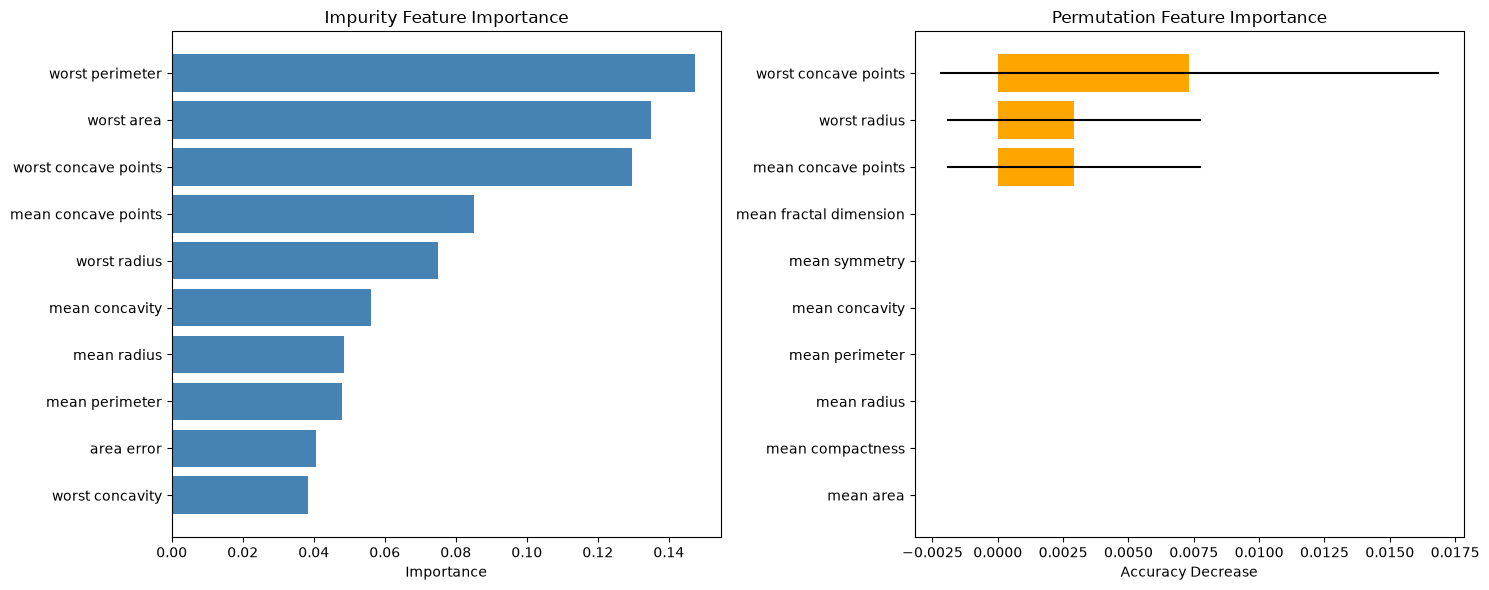


===== CÂU D =====
Số feature ban đầu: 30
Số feature sau khi thêm nhiễu: 31
Noise Impurity: 0.0027
Noise Permutation: 0.0000
Noise Impurity Rank: 31/31
Noise Permutation Rank: 3/31
Kiểm chứng noise_impurity > noise_perm: True
Kiểm chứng noise_perm < 0.005: True

===== BẢNG TỔNG HỢP =====
                    feature  impurity  permutation
27     worst concave points  0.147247     0.008059
22          worst perimeter  0.129436    -0.004029
20             worst radius  0.111091    -0.001099
23               worst area  0.110161    -0.001099
6            mean concavity  0.073269     0.000000
7       mean concave points  0.067597     0.002564
0               mean radius  0.045281     0.000000
3                 mean area  0.044050     0.000000
13               area error  0.033571     0.000000
2            mean perimeter  0.032195     0.000000
26          worst concavity  0.028562     0.000000
5          mean compactness  0.021004     0.000000
21            worst texture  0.020755     0.0000

In [11]:


# ==========================================
# CHUẨN BỊ DỮ LIỆU
# ==========================================

X_train, y_train = data_manager.get_train()
X_val, y_val = data_manager.get_val()

feature_names = np.asarray(feature_names)

# ==========================================
# CÂU A: IMPURITY FEATURE IMPORTANCE
# ==========================================

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

impurity_importance = model.feature_importances_

print("===== CÂU A =====")

df_impurity = pd.DataFrame({
    "feature": feature_names,
    "importance": impurity_importance
}).sort_values("importance", ascending=False)

print(df_impurity)


# ==========================================
# CÂU B: PERMUTATION FEATURE IMPORTANCE
# ==========================================

perm_result = permutation_importance(
    model,
    X_val,
    y_val,
    n_repeats=30,
    random_state=42,
    scoring="accuracy"
)

perm_importance = perm_result.importances_mean

df_perm = pd.DataFrame({
    "feature": feature_names,
    "importance": perm_importance,
    "std": perm_result.importances_std
}).sort_values("importance", ascending=False)

print("\n===== CÂU B =====")
print(df_perm)


# ==========================================
# CÂU C: SO SÁNH HAI PHƯƠNG PHÁP
# ==========================================

# Lấy top 5 feature của mỗi phương pháp
top5_impurity = df_impurity.head(5)["feature"].tolist()

top5_perm = df_perm.head(5)["feature"].tolist()

# Tìm các feature xuất hiện trong cả hai danh sách
common_features = set(top5_impurity) & set(top5_perm)

overlap = len(common_features)

# Tính tương quan Spearman
rank_corr, p_value = spearmanr(
    impurity_importance,
    perm_importance
)

print("\n===== CÂU C =====")

print("Top 5 Impurity:", top5_impurity)
print("Top 5 Permutation:", top5_perm)

print("Feature chung:", common_features)
print("Overlap:", overlap)

print(f"Spearman Correlation: {rank_corr:.4f}")
print(f"P-value: {p_value:.4f}")

print("Kiểm chứng overlap < 5:", overlap < 5)


# ==========================================
# VẼ BIỂU ĐỒ SO SÁNH
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Impurity Importance
top_imp = df_impurity.head(10).sort_values("importance")

axes[0].barh(
    top_imp["feature"],
    top_imp["importance"],
    color="steelblue"
)

axes[0].set_title("Impurity Feature Importance")
axes[0].set_xlabel("Importance")

# Permutation Importance
top_perm = df_perm.head(10).sort_values("importance")

axes[1].barh(
    top_perm["feature"],
    top_perm["importance"],
    xerr=top_perm["std"],
    color="orange"
)

axes[1].set_title("Permutation Feature Importance")
axes[1].set_xlabel("Accuracy Decrease")

plt.tight_layout()
plt.show()


# ==========================================
# CÂU D: THÊM FEATURE NHIỄU NGẪU NHIÊN
# ==========================================

rng = np.random.default_rng(0)

# Sinh dữ liệu nhiễu độc lập cho Train và Validation
noise_train = rng.normal(size=len(X_train))
noise_val = rng.normal(size=len(X_val))

# Thêm cột nhiễu vào cuối tập dữ liệu
X_train_noise = np.column_stack(
    (X_train, noise_train)
)

X_val_noise = np.column_stack(
    (X_val, noise_val)
)

# Bổ sung tên feature
feature_names_noise = np.append(
    feature_names,
    "random_noise"
)

# Huấn luyện mô hình mới với 31 features
noise_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

noise_model.fit(X_train_noise, y_train)

# ------------------------------------------
# Impurity Importance của feature nhiễu
# ------------------------------------------

noise_impurity_all = noise_model.feature_importances_

noise_impurity = noise_impurity_all[-1]

# ------------------------------------------
# Permutation Importance của feature nhiễu
# ------------------------------------------

noise_perm_result = permutation_importance(
    noise_model,
    X_val_noise,
    y_val,
    n_repeats=30,
    random_state=42,
    scoring="accuracy"
)

noise_perm_all = noise_perm_result.importances_mean

noise_perm = noise_perm_all[-1]

# ------------------------------------------
# Tính thứ hạng của feature nhiễu
# ------------------------------------------

noise_impurity_rank = int(
    np.sum(noise_impurity_all > noise_impurity) + 1
)

noise_perm_rank = int(
    np.sum(noise_perm_all > noise_perm) + 1
)

print("\n===== CÂU D =====")

print("Số feature ban đầu:", X_train.shape[1])

print("Số feature sau khi thêm nhiễu:",
      X_train_noise.shape[1])

print(f"Noise Impurity: {noise_impurity:.4f}")

print(f"Noise Permutation: {noise_perm:.4f}")

print(f"Noise Impurity Rank: {noise_impurity_rank}/31")

print(f"Noise Permutation Rank: {noise_perm_rank}/31")

print(
    "Kiểm chứng noise_impurity > noise_perm:",
    noise_impurity > noise_perm
)

print(
    "Kiểm chứng noise_perm < 0.005:",
    noise_perm < 0.005
)


# ==========================================
# BẢNG TỔNG HỢP SAU KHI THÊM NHIỄU
# ==========================================

df_noise = pd.DataFrame({
    "feature": feature_names_noise,
    "impurity": noise_impurity_all,
    "permutation": noise_perm_all
})

print("\n===== BẢNG TỔNG HỢP =====")

print(
    df_noise.sort_values(
        "impurity",
        ascending=False
    )
)

# bai 6

===== CÂU A =====
 n_estimators max_features  val_acc  n_correct  train_time  predict_time  avg_depth
           10         sqrt 0.956044         87    0.016992      0.001126   6.300000
           10         log2 0.956044         87    0.016480      0.001355   6.300000
           10         None 0.956044         87    0.044703      0.002294   5.300000
           50         sqrt 0.956044         87    0.145250      0.008216   6.240000
           50         log2 0.967033         88    0.084063      0.003873   6.240000
           50         None 0.945055         86    0.139161      0.003896   5.440000
          100         sqrt 0.956044         87    0.141969      0.007277   6.190000
          100         log2 0.956044         87    0.131693      0.007365   6.320000
          100         None 0.934066         85    0.287543      0.007729   5.390000
          300         sqrt 0.956044         87    0.425341      0.021133   6.260000
          300         log2 0.956044         87    0.388745

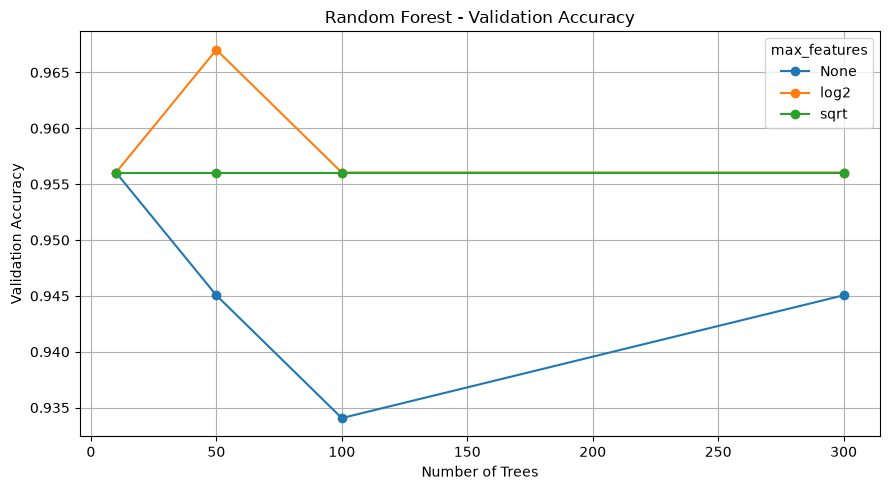

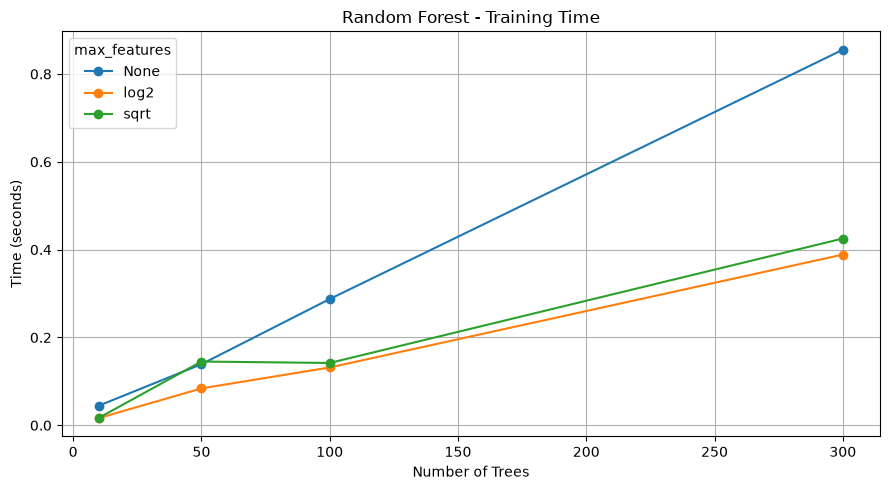

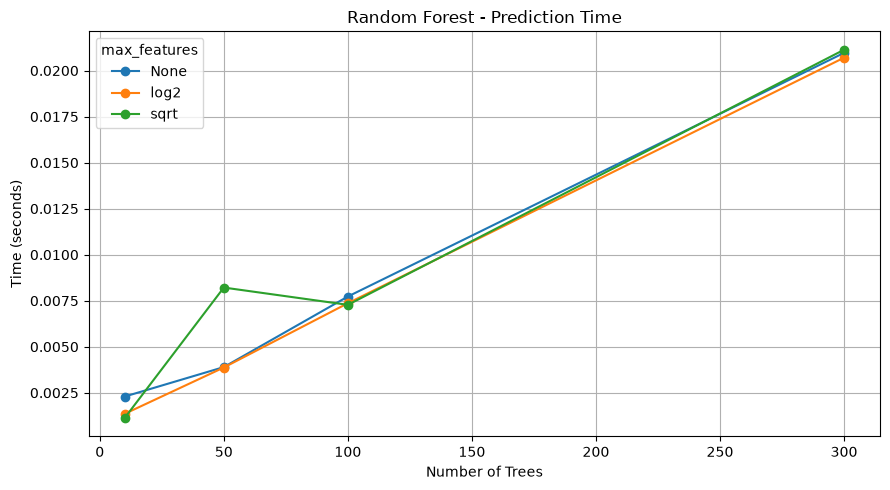


===== CÂU C =====

Mô hình có Accuracy cao nhất:
n_estimators          50
max_features        log2
val_acc         0.967033
n_correct             88
train_time      0.084063
predict_time    0.003873
avg_depth           6.24
Name: 4, dtype: object

Các mô hình nằm trong phạm vi chấp nhận:
 n_estimators max_features  val_acc  n_correct  train_time  predict_time  avg_depth
           10         sqrt 0.956044         87    0.016992      0.001126       6.30
           10         log2 0.956044         87    0.016480      0.001355       6.30
           10         None 0.956044         87    0.044703      0.002294       5.30
           50         sqrt 0.956044         87    0.145250      0.008216       6.24
           50         log2 0.967033         88    0.084063      0.003873       6.24
          100         sqrt 0.956044         87    0.141969      0.007277       6.19
          100         log2 0.956044         87    0.131693      0.007365       6.32
          300         sqrt 0.956044   

In [12]:

# ==========================================
# CHUẨN BỊ DỮ LIỆU
# ==========================================

X_train, y_train = data_manager.get_train()
X_val, y_val = data_manager.get_val()

n_estimators_list = [10, 50, 100, 300]

max_features_list = ["sqrt", "log2", None]

results = []

models = {}

# ==========================================
# CÂU A: HUẤN LUYỆN 12 MÔ HÌNH
# ==========================================

for n in n_estimators_list:

    for mf in max_features_list:

        model = RandomForestClassifier(
            n_estimators=n,
            max_features=mf,
            random_state=42
        )

        # Đo thời gian huấn luyện
        start = time.perf_counter()

        model.fit(X_train, y_train)

        train_time = time.perf_counter() - start

        # Đo thời gian dự đoán
        start = time.perf_counter()

        y_val_pred = model.predict(X_val)

        predict_time = time.perf_counter() - start

        # Tính Accuracy
        val_acc = accuracy_score(y_val, y_val_pred)

        # Tính số mẫu dự đoán đúng
        n_correct = round(val_acc * len(y_val))

        # Tính độ sâu trung bình của các cây
        avg_depth = np.mean([
            tree.get_depth()
            for tree in model.estimators_
        ])

        # Chuyển None thành chuỗi để dễ tạo bảng
        mf_name = str(mf)

        # Lưu kết quả
        results.append({
            "n_estimators": n,
            "max_features": mf_name,
            "val_acc": val_acc,
            "n_correct": n_correct,
            "train_time": train_time,
            "predict_time": predict_time,
            "avg_depth": avg_depth
        })

        # Lưu mô hình
        models[(n, mf_name)] = model

df_rf = pd.DataFrame(results)

print("===== CÂU A =====")
print(df_rf.to_string(index=False))


# ==========================================
# CÂU B: TẠO BẢNG PIVOT
# ==========================================

# Bảng Accuracy
pivot_acc = df_rf.pivot(
    index="n_estimators",
    columns="max_features",
    values="val_acc"
)

# Bảng thời gian huấn luyện
pivot_train_time = df_rf.pivot(
    index="n_estimators",
    columns="max_features",
    values="train_time"
)

# Bảng thời gian dự đoán
pivot_predict_time = df_rf.pivot(
    index="n_estimators",
    columns="max_features",
    values="predict_time"
)

print("\n===== CÂU B =====")

print("\nValidation Accuracy:")
print(pivot_acc)

print("\nTraining Time:")
print(pivot_train_time)

print("\nPrediction Time:")
print(pivot_predict_time)


# ==========================================
# VẼ BIỂU ĐỒ
# ==========================================

# Biểu đồ Accuracy
pivot_acc.plot(
    marker="o",
    figsize=(9, 5)
)

plt.title("Random Forest - Validation Accuracy")
plt.xlabel("Number of Trees")
plt.ylabel("Validation Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

# Biểu đồ thời gian huấn luyện
pivot_train_time.plot(
    marker="o",
    figsize=(9, 5)
)

plt.title("Random Forest - Training Time")
plt.xlabel("Number of Trees")
plt.ylabel("Time (seconds)")
plt.grid(True)
plt.tight_layout()
plt.show()

# Biểu đồ thời gian dự đoán
pivot_predict_time.plot(
    marker="o",
    figsize=(9, 5)
)

plt.title("Random Forest - Prediction Time")
plt.xlabel("Number of Trees")
plt.ylabel("Time (seconds)")
plt.grid(True)
plt.tight_layout()
plt.show()


# ==========================================
# CÂU C: LỰA CHỌN MÔ HÌNH TRIỂN KHAI
# ==========================================

# Tìm số mẫu dự đoán đúng cao nhất
best_n_correct = df_rf["n_correct"].max()

# Tìm mô hình có Accuracy cao nhất
# Nếu bằng nhau, ưu tiên huấn luyện nhanh hơn
best_model_info = df_rf.sort_values(
    ["n_correct", "train_time"],
    ascending=[False, True]
).iloc[0]

# Chấp nhận mô hình dự đoán đúng ít hơn
# mô hình tốt nhất không quá 1 mẫu
within_noise = df_rf[
    df_rf["n_correct"] >= best_n_correct - 1
]

# Số lượng mô hình đạt điều kiện
n_within_noise = len(within_noise)

# Chọn mô hình có thời gian huấn luyện thấp nhất
ship = within_noise.sort_values(
    "train_time",
    ascending=True
).iloc[0]

# Lấy mô hình đã huấn luyện từ dictionary
ship_model = models[
    (
        int(ship["n_estimators"]),
        ship["max_features"]
    )
]

print("\n===== CÂU C =====")

print("\nMô hình có Accuracy cao nhất:")
print(best_model_info)

print("\nCác mô hình nằm trong phạm vi chấp nhận:")
print(within_noise.to_string(index=False))

print("\nSố mô hình đạt điều kiện:", n_within_noise)

print("\nMô hình được chọn để triển khai (SHIP):")
print(ship)

print("\nKiểm chứng:")

print(
    "SHIP không chậm hơn mô hình chính xác nhất:",
    ship["train_time"] <= best_model_info["train_time"]
)

print(
    "n_within_noise == 8:",
    n_within_noise == 8
)